                       data coefficients   AUC  false positive rate at 50%  debris flows caught at 50%
train (southern California)    published 0.862                       0.049                       0.478
train (southern California)         mine 0.862                       0.049                       0.478
        test (other states)    published 0.745                       0.454                       0.842
        test (other states)         mine 0.745                       0.454                       0.842


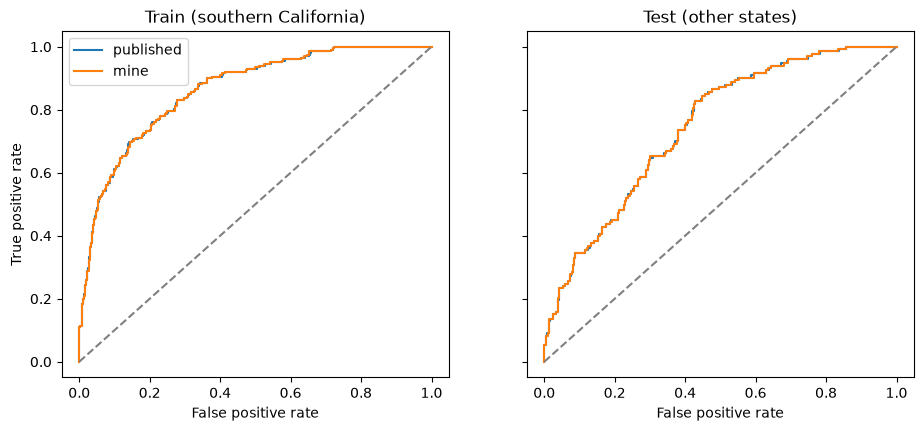

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

d = pd.read_csv("../data/model_table.csv")
cols = ["TR", "FR", "SR"]
s16 = d[d["source"] == "Staley and others (2016)"]
train = s16[s16["state"] == "CA"]
test = s16[s16["state"] != "CA"]

fit_train = sm.Logit(train["Response"], sm.add_constant(train[cols])).fit(disp=0)

def p_mine(data):
    return fit_train.predict(sm.add_constant(data[cols], has_constant="add"))

def p_pub(data):
    X = -3.63 + 0.41*data["TR"] + 0.67*data["FR"] + 0.70*data["SR"]
    return np.exp(X) / (1 + np.exp(X))

rows = []
for name, data in [("train (southern California)", train), ("test (other states)", test)]:
    y = data["Response"]
    for label, p in [("published", p_pub(data)), ("mine", p_mine(data))]:
        tn, fp, fn, tp = confusion_matrix(y, p > 0.5).ravel()
        rows.append({"data": name, "coefficients": label,
                     "AUC": round(roc_auc_score(y, p), 3),
                     "false positive rate at 50%": round(fp / (fp + tn), 3),
                     "debris flows caught at 50%": round(tp / (tp + fn), 3)})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, (name, data) in zip(ax, [("Train (southern California)", train), ("Test (other states)", test)]):
    y = data["Response"]
    for label, p in [("published", p_pub(data)), ("mine", p_mine(data))]:
        fpr, tpr, _ = roc_curve(y, p)
        a.plot(fpr, tpr, label=label)
    a.plot([0, 1], [0, 1], "--", color="gray")
    a.set_title(name)
    a.set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")
ax[0].legend()
plt.savefig("../notes/roc_train_test.png", dpi=150)
plt.show()
